# 03. "50% 할인"은 진짜 파격 세일일까? — 할인 유형 진정성 검증

> 겜누리 분석 A1 확장 · 최근 1년 가격 이력이 있는 유료 게임 908개

## 한눈에 보기
**질문** "지금 50% 할인 중" 표시, 진짜 파격 세일일까? 아니면 1년 내내 붙어 있는 상시 할인가일까?

**답**
1. **같은 할인율도 값어치가 다르다.** 최대 할인율은 84% vs 80%로 비슷한데, 1년 평균 구매가는 정가의 73% vs 80%였다.
2. **겜누리 화면의 최저가(전 스토어) 기준으로는 "할인 중"이 평상시 상태다.** 게임의 71%가 1년의 절반 넘게 할인 중이다. (Steam만 보면 0%)
3. 유형 간 차이는 생각보다 작고(정가의 9~27% 할인), 4유형은 편의상의 구분이다.

**제안** "진짜 딜" 표시는 할인율이 아니라 **이 게임의 1년 가격 분포에서 지금 가격의 위치**로 만든다.

> **읽는 법** ★ 는 2분 안에 보여 줄 핵심 차트다. "부록"은 질문이 나왔을 때 보는 내용이다. 위에서 아래로 실행하면 된다.

## 1단계. 데이터 분석 설계

### 4가지 유형 (연간 할인 빈도 × 최대 할인율, 각 중앙값 기준)
| | 최대 할인율 높음 | 최대 할인율 낮음 |
|---|---|---|
| **할인 자주** | **상시 세일형** — 자주, 깊게 | **미끼 할인형** — 자주, 얕게 |
| **할인 드물게** | **희소 빅세일형** — 드물지만 깊게 | **정가 고수형** — 거의 안 함 |

### 쓰는 지표 (최근 365일)
| 지표 | 뜻 |
|---|---|
| 연간 할인 빈도 | 할인(10% 이상)이 **시작된 횟수** |
| 최대 할인율 | 그 기간의 최대 할인율(%) |
| **실질 평균 구매가** | 매일 사는 사람이 평균 내는 가격 ÷ 정가 (1.0이면 정가) |
| 할인 일수 비율 | 1년 중 할인 중이었던 날의 비율 |
| 놓치면 기다리는 일수 | 할인이 아닌 날부터 **다음 할인 시작까지** 평균 일수 |
| 할인 표시의 정확도 | 50% 이상 할인이 **표시된 날** 중, 가격이 1년 최저가의 105% 이내인 날의 비율 |

### 가설과 검정 방법
| # | 가설 (쉬운 말) | 쓰는 검정 | 이 방법을 고른 이유 |
|---|---|---|---|
| H1 | 유형에 따라 **실질 구매가가 다르다** | Kruskal-Wallis | 가격 비율은 정규분포가 아니고 4개 집단을 비교하므로 비모수 검정을 쓴다 |
| H2 | **최대 할인율이 비슷해도** 구매가가 다르다 (상시 vs 희소) | Mann-Whitney | "80%대 할인"이라는 숫자만으로 구분이 안 됨을 보인다 |
| H3 | 희소 빅세일형은 **놓치면 더 오래 기다린다** | Mann-Whitney (단측) | "세일을 놓치면 한참 기다린다"는 주장을 확인한다 |
| H4 | **자주 할인할수록 할인이 얕다** (미끼 할인) | Spearman 순위 상관 (단측) | 빈도와 깊이가 맞바꿔지는지를 비선형 관계까지 본다 |
| H5 | 유형별로 **"50% 이상" 표시의 정확도**가 다르다 | Kruskal-Wallis | 배지를 만든다면 어느 유형에서 틀리기 쉬운지 본다 |

### 스토어 기준
- **Steam(공식 스토어)** 으로 유형을 나눈다. "상시 세일"은 한 스토어의 가격 정책이라, 여러 스토어의 최저가를 섞으면 키 판매점의 할인이 끼어든다.
- 겜누리 화면은 **전 스토어 최저가**를 보여 주므로, 그 기준으로도 계산해 **두 기준이 얼마나 다른지** 비교한다.

**쓰는 도구** pandas(정리·집계) · scipy.stats(검정) · matplotlib(차트)

## 2단계. 데이터 준비

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from _common import ROOT, SALE_MIN_PCT, daily_series, load_price_history, setup_plot, verdict
setup_plot()

In [18]:
games = pd.read_csv(ROOT / "analysis" / "game_list" / "games_1000.csv", encoding="utf-8-sig")
games["name_ko"] = games.name_ko.fillna(games.name)
prices = load_price_history(games.game_id.tolist())

print(f"가격 이력 {len(prices):,}행 · 게임 {prices.game_id.nunique():,}개 · "
      f"{prices.collected_at.min():%Y-%m-%d} ~ {prices.collected_at.max():%Y-%m-%d}")
prices.store.value_counts().head(8).rename("행 수").to_frame().T

가격 이력 561,996행 · 게임 1,000개 · 2024-12-07 ~ 2026-11-26


store,dreamgame,gamesporium,gamebillet,gamersgate,steam,fanatical,humblestore,gog
행 수,153996,43587,39822,37949,32763,26009,20974,20731


In [19]:
prices.info()          # 컬럼 타입과 결측치 확인

<class 'pandas.DataFrame'>
RangeIndex: 561996 entries, 0 to 561995
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   game_id       561996 non-null  int64         
 1   store         561996 non-null  str           
 2   edition       561996 non-null  str           
 3   price_krw     561996 non-null  int64         
 4   regular_krw   561113 non-null  float64       
 5   discount_pct  561113 non-null  float64       
 6   collected_at  561996 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(2), int64(2), str(2)
memory usage: 30.0 MB


## 3단계. 데이터 가공
1. 게임마다 **일별 최저가·할인율**을 만들고, 가격이 안 바뀐 날도 직전 값으로 이어 채워 **달력 날짜 단위**로 펼친다. (그래야 "할인 일수 비율"과 "기다리는 일수"가 정확하다)
2. 최근 365일의 지표를 계산한다. 이력이 1년 미만이거나 무료인 게임은 뺀다.
3. **Steam만**, **전 스토어 최저가** 두 기준으로 각각 계산한다.

In [20]:
YEAR = 365
NEAR_LOW = 1.05      # 1년 최저가의 105% 이내면 "최저가 근처"
TYPES = ["상시 세일형", "희소 빅세일형", "정가 고수형", "미끼 할인형"]
END = prices.collected_at.max().normalize()


def calendar_series(g: pd.DataFrame) -> pd.DataFrame:
    d = daily_series(g).set_index("day")[["price_krw", "discount_pct"]]
    return d.reindex(pd.date_range(d.index.min(), END)).ffill()


def game_metrics(g: pd.DataFrame, regular):
    cal = calendar_series(g)
    if cal.index.min() > END - pd.Timedelta(days=YEAR - 1):
        return None                                          # 이력 1년 미만
    w = cal.loc[END - pd.Timedelta(days=YEAR - 1):END]
    price, disc = w.price_krw.to_numpy(float), w.discount_pct.to_numpy(float)
    if price.max() == 0:
        return None                                          # 무료
    sale = disc >= SALE_MIN_PCT
    starts = np.flatnonzero(sale & ~np.r_[False, sale[:-1]])  # 할인이 시작된 날
    reg = regular if regular and regular > 0 else price.max()
    off = np.flatnonzero(~sale)
    nxt = np.searchsorted(starts, off, side="right")
    has_next = nxt < len(starts)
    waits = starts[nxt[has_next]] - off[has_next]            # 할인이 아닌 날 → 다음 할인 시작까지 일수
    big = disc >= 50
    return {"freq": len(starts), "maxdisc": disc.max(), "sale_share": sale.mean(),
            "avg_ratio": np.minimum(price / reg, 1.0).mean(),
            "wait_days": waits.mean() if len(waits) else np.nan,
            "deal_precision": (price[big] <= price.min() * NEAR_LOW).mean() if big.any() else np.nan}


def metrics_table(prices_sub: pd.DataFrame) -> pd.DataFrame:
    regular = prices_sub.groupby("game_id").regular_krw.median()
    rows = {}
    for gid, g in prices_sub.groupby("game_id"):
        m = game_metrics(g, regular.get(gid))
        if m:
            rows[gid] = m
    return pd.DataFrame(rows).T.astype(float)

In [21]:
m_steam = metrics_table(prices[prices.store == "steam"])
m_all = metrics_table(prices)
common = m_steam.index.intersection(m_all.index)
m_steam, m_all = m_steam.loc[common].copy(), m_all.loc[common].copy()
print(f"분석 대상 {len(common)}개 게임 (최근 365일, 이력 1년 이상 · 유료)")
pd.concat({"Steam만": m_steam.describe().T[["mean", "25%", "50%", "75%"]],
           "전 스토어 최저가": m_all.describe().T[["mean", "25%", "50%", "75%"]]}, axis=1).round(2)

분석 대상 908개 게임 (최근 365일, 이력 1년 이상 · 유료)


Steam만                      전 스토어 최저가                     
                 mean    25%    50%    75%      mean    25%    50%    75%
freq             8.25   7.00   9.00  10.00      6.05   1.00   6.00  10.00
maxdisc         66.42  50.00  75.00  82.50     69.87  57.00  75.00  87.00
sale_share       0.28   0.22   0.29   0.36      0.70   0.43   0.83   0.99
avg_ratio        0.81   0.74   0.81   0.89      0.49   0.26   0.46   0.71
wait_days       22.86  15.37  18.25  26.00     15.30   4.55   9.99  18.42
deal_precision   0.61   0.21   0.65   1.00      0.29   0.06   0.17   0.44

## 4단계. 데이터 분석

### 먼저 확인 — "할인 중" 표시는 변별력이 있나? ★
거의 모든 게임이 거의 항상 할인 중이면, "할인 중"이라는 표시는 정보가 되지 못한다.

,절반 이상의 날 할인 중인 게임(%),할인 일수 비율 중앙값(%),최대 할인율 50% 이상인 게임(%)
겜누리 최저가(전 스토어),70.8,83.4,85.6
Steam만,0.0,29.3,83.7


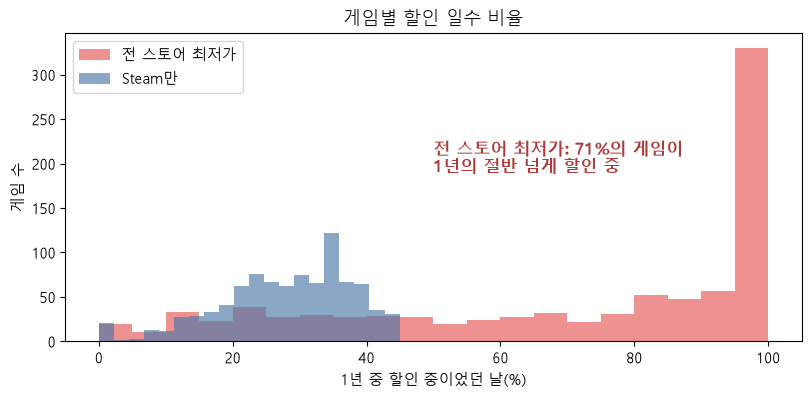

In [22]:
share_all = (m_all.sale_share >= .5).mean() * 100
share_steam = (m_steam.sale_share >= .5).mean() * 100
display(pd.DataFrame({
    "절반 이상의 날 할인 중인 게임(%)": [share_all, share_steam],
    "할인 일수 비율 중앙값(%)": [m_all.sale_share.median() * 100, m_steam.sale_share.median() * 100],
    "최대 할인율 50% 이상인 게임(%)": [(m_all.maxdisc >= 50).mean() * 100, (m_steam.maxdisc >= 50).mean() * 100],
}, index=["겜누리 최저가(전 스토어)", "Steam만"]).round(1))

fig, ax = plt.subplots(figsize=(9.5, 4))
ax.hist(m_all.sale_share * 100, bins=20, alpha=.65, label="전 스토어 최저가", color="#e45756")
ax.hist(m_steam.sale_share * 100, bins=20, alpha=.65, label="Steam만", color="#4c78a8")
ax.text(50, ax.get_ylim()[1] * .55, f"전 스토어 최저가: {share_all:.0f}%의 게임이\n1년의 절반 넘게 할인 중", fontsize=12, color="#b03a3a", fontweight="bold")
ax.set(title="게임별 할인 일수 비율", xlabel="1년 중 할인 중이었던 날(%)", ylabel="게임 수"); ax.legend(loc="upper left")
plt.show()

**차트 읽는 법** 빨강(전 스토어 최저가)이 오른쪽 끝에 몰려 있으면, 키 판매점까지 포함한 최저가에서는 **"할인 중"이 평상시 상태**라는 뜻이다. 파랑(Steam)은 할인 중인 날이 일부라서 "세일 기간"이 실제로 구분된다. 그래서 유형 분류는 Steam을 기준으로 한다.

### 유형 분류 — 연간 할인 빈도 × 최대 할인율
각 기준의 **중앙값**으로 4분할한다.

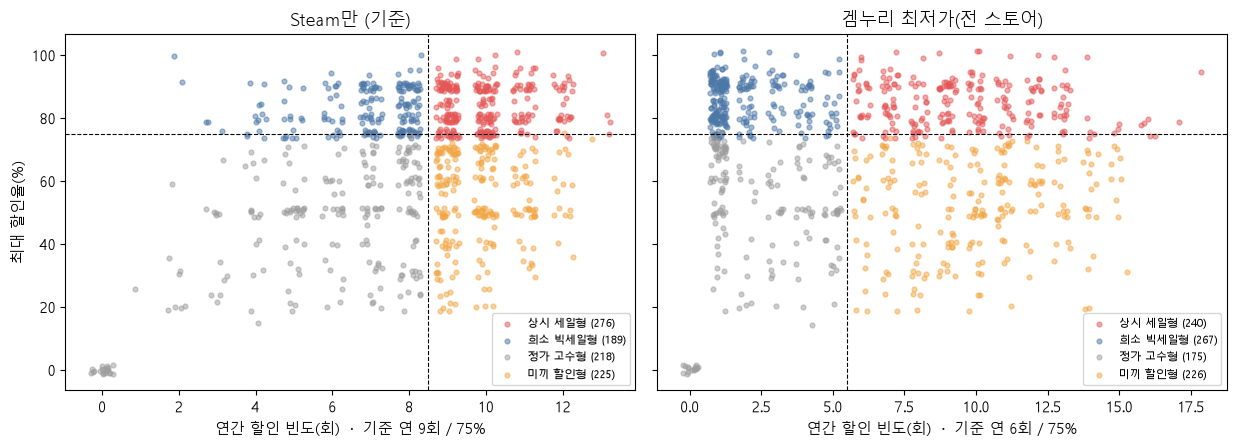

In [23]:
def classify(t: pd.DataFrame, f_thr: float, d_thr: float) -> np.ndarray:
    hi_f, hi_d = t.freq >= f_thr, t.maxdisc >= d_thr
    return np.select([hi_f & hi_d, ~hi_f & hi_d, ~hi_f & ~hi_d, hi_f & ~hi_d], TYPES, default="")

COLORS = dict(zip(TYPES, ["#e45756", "#4c78a8", "#9d9d9d", "#f2a541"]))
thr = {}
for name, t in (("steam", m_steam), ("all", m_all)):
    thr[name] = (t.freq.median(), t.maxdisc.median())
    t["type"] = classify(t, *thr[name])

rng = np.random.default_rng(3)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for ax, (name, t, title) in zip(axes, (("steam", m_steam, "Steam만 (기준)"), ("all", m_all, "겜누리 최저가(전 스토어)"))):
    for ty in TYPES:
        s = t[t.type == ty]
        ax.scatter(s.freq + rng.uniform(-.3, .3, len(s)), s.maxdisc + rng.uniform(-1.5, 1.5, len(s)),
                   s=12, alpha=.5, color=COLORS[ty], label=f"{ty} ({len(s)})")
    f_thr, d_thr = thr[name]
    ax.axvline(f_thr - .5, color="black", lw=.8, ls="--"); ax.axhline(d_thr, color="black", lw=.8, ls="--")
    ax.set(title=title, xlabel=f"연간 할인 빈도(회)  ·  기준 연 {f_thr:.0f}회 / {d_thr:.0f}%"); ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("최대 할인율(%)")
plt.tight_layout(); plt.show()

**차트 읽는 법** 점 하나가 게임 하나다(겹치지 않게 약간 흩뿌렸다). 오른쪽 위 = 상시 세일형, 왼쪽 위 = 희소 빅세일형, 왼쪽 아래 = 정가 고수형, 오른쪽 아래 = 미끼 할인형. 점이 경계에서 뚜렷하게 갈리지 않고 **연속적으로 퍼져 있어서** 4유형은 편의상의 구분이다. 두 패널의 모양이 다른 것은 **스토어 기준에 따라 같은 게임의 유형이 달라진다**는 뜻이다(부록에서 일치도를 잰다).

### 유형별 실질 평균 구매가 ★
**정가를 1.0**으로 했을 때, 1년 동안 매일 사는 사람이 평균적으로 내는 가격이다. 값이 작을수록 실제로 싸게 살 수 있다.

,게임수,빈도중앙값,최대할인중앙값,할인일수비율,평균구매가,기다리는일수,표시정확도
type,,,,,,,
상시 세일형,276,10.0,84.0,0.34,0.73,15.82,0.50
희소 빅세일형,189,7.0,80.0,0.24,0.80,25.52,0.62
정가 고수형,218,6.0,50.0,0.18,0.91,29.90,0.77
미끼 할인형,225,10.0,50.0,0.33,0.84,15.80,0.65


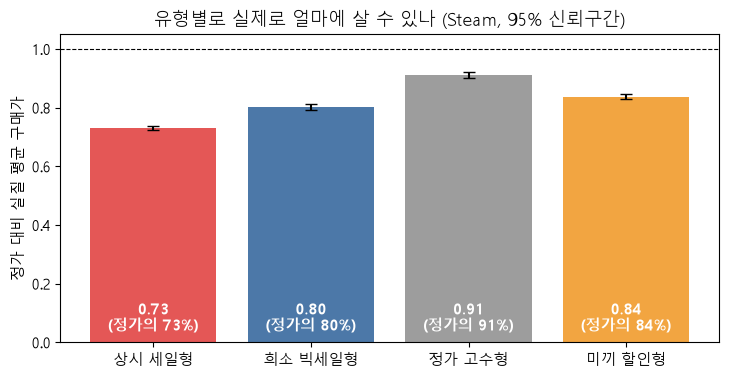

In [24]:
def boot_ci(x, n=2000, seed=0):
    r = np.random.default_rng(seed)
    return np.percentile([r.choice(x, len(x)).mean() for _ in range(n)], [2.5, 97.5])

summary = m_steam.groupby("type").agg(게임수=("freq", "size"), 빈도중앙값=("freq", "median"), 최대할인중앙값=("maxdisc", "median"),
                                      할인일수비율=("sale_share", "mean"), 평균구매가=("avg_ratio", "mean"),
                                      기다리는일수=("wait_days", "median"), 표시정확도=("deal_precision", "mean")).reindex(TYPES)
display(summary.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4))
means = summary["평균구매가"].to_numpy()
cis = np.array([boot_ci(m_steam.loc[m_steam.type == t, "avg_ratio"].to_numpy()) for t in TYPES])
ax.bar(TYPES, means, color=[COLORS[t] for t in TYPES], yerr=[means - cis[:, 0], cis[:, 1] - means], capsize=4)
for i, v in enumerate(means):
    ax.text(i, 0.04, f"{v:.2f}\n(정가의 {v * 100:.0f}%)", ha="center", color="white", fontweight="bold")
ax.axhline(1, color="black", lw=.8, ls="--")
ax.set(ylim=(0, 1.05), ylabel="정가 대비 실질 평균 구매가", title="유형별로 실제로 얼마에 살 수 있나 (Steam, 95% 신뢰구간)")
plt.show()

**차트 읽는 법** 막대가 낮을수록 평균적으로 싸게 살 수 있는 유형이다. 오차 막대(95% 신뢰구간)가 겹치면 차이가 불확실하다. 1.0(점선)에 가까우면 사실상 정가에 사는 것과 같다.

### 검정 — 가설 H1 ~ H5
> **주의** 유형을 "빈도 × 깊이"로 정의했고 평균 구매가도 빈도와 깊이로 결정되는 값이라, H1의 유의함은 **구조적으로 당연**하다. 의미가 있는 것은 p값이 아니라 **차이의 크기**(정가 대비 몇 %)다.

In [25]:
def kruskal(t, col):
    groups = [t.loc[t.type == ty, col].dropna() for ty in TYPES]
    h, p = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    return p, (h - len(TYPES) + 1) / (n - len(TYPES))              # p값, 효과 크기 ε²

a = m_steam[m_steam.type == "상시 세일형"]
b = m_steam[m_steam.type == "희소 빅세일형"]

p_h1, eps_h1 = kruskal(m_steam, "avg_ratio")
p_h2 = stats.mannwhitneyu(a.avg_ratio, b.avg_ratio).pvalue
p_h2_disc = stats.mannwhitneyu(a.maxdisc, b.maxdisc).pvalue
p_h3 = stats.mannwhitneyu(b.wait_days.dropna(), a.wait_days.dropna(), alternative="greater").pvalue
rho_s = stats.spearmanr(m_steam.freq, m_steam.maxdisc, alternative="less")
rho_a = stats.spearmanr(m_all.freq, m_all.maxdisc, alternative="less")
p_h5, eps_h5 = kruskal(m_steam, "deal_precision")

print(f"H1 유형별 구매가 차이        : p = {p_h1:.3g}, 효과 크기 ε² = {eps_h1:.2f}")
print(f"H2 상시 vs 희소 (최대 할인율 {a.maxdisc.median():.0f}% vs {b.maxdisc.median():.0f}%, p = {p_h2_disc:.3g}) → 구매가 {a.avg_ratio.mean():.2f} vs {b.avg_ratio.mean():.2f}, p = {p_h2:.3g}")
print(f"H3 놓치면 기다리는 일수      : 희소 {b.wait_days.median():.1f}일 vs 상시 {a.wait_days.median():.1f}일, p = {p_h3:.3g}")
print(f"H4 빈도-할인율 Spearman     : Steam ρ = {rho_s.statistic:+.2f} (ρ<0 단측 p = {rho_s.pvalue:.3g}), 전 스토어 ρ = {rho_a.statistic:+.2f}")
print(f"H5 할인 표시의 정확도        : p = {p_h5:.3g}, 효과 크기 ε² = {eps_h5:.2f}")

by_type = m_steam.groupby("type").deal_precision.mean()
result = pd.DataFrame([
    ["H1 유형별 실질 구매가가 다르다", f"{summary['평균구매가'].idxmin()} {summary['평균구매가'].min():.2f} ~ {summary['평균구매가'].idxmax()} {summary['평균구매가'].max():.2f}", p_h1],
    ["H2 최대 할인율이 비슷해도 구매가가 다르다", f"할인율 {a.maxdisc.median():.0f}% vs {b.maxdisc.median():.0f}% · 구매가 {a.avg_ratio.mean():.2f} vs {b.avg_ratio.mean():.2f}", p_h2],
    ["H3 희소 빅세일형은 놓치면 더 오래 기다린다", f"{b.wait_days.median():.1f}일 vs {a.wait_days.median():.1f}일", p_h3],
    ["H4 자주 할인할수록 할인이 얕다(미끼 할인)", f"Spearman ρ = {rho_s.statistic:+.2f}", rho_s.pvalue],
    ["H5 유형별 \"50% 이상\" 표시의 정확도가 다르다", f"{by_type.min():.2f} ~ {by_type.max():.2f}", p_h5],
], columns=["가설", "핵심 수치", "p값"])
result["판정(α=0.05)"] = result["p값"].map(verdict)
result["p값"] = result["p값"].map(lambda p: f"{p:.3g}" if p < 0.999 else "> 0.999")

H1 유형별 구매가 차이        : p = 1.21e-108, 효과 크기 ε² = 0.55
H2 상시 vs 희소 (최대 할인율 84% vs 80%, p = 0.0413) → 구매가 0.73 vs 0.80, p = 3.55e-30
H3 놓치면 기다리는 일수      : 희소 25.5일 vs 상시 15.8일, p = 2.88e-46
H4 빈도-할인율 Spearman     : Steam ρ = +0.23 (ρ<0 단측 p = 1), 전 스토어 ρ = -0.13
H5 할인 표시의 정확도        : p = 5.47e-11, 효과 크기 ε² = 0.06


## 5단계. 결론 도출

In [26]:
result

,가설,핵심 수치,p값,판정(α=0.05)
0,H1 유형별 실질 구매가가 다르다,상시 세일형 0.73 ~ 정가 고수형 0.91,1.21e-108,채택 (유의)
1,H2 최대 할인율이 비슷해도 구매가가 다르다,할인율 84% vs 80% · 구매가 0.73 vs 0.80,3.55e-30,채택 (유의)
2,H3 희소 빅세일형은 놓치면 더 오래 기다린다,25.5일 vs 15.8일,2.88e-46,채택 (유의)
3,H4 자주 할인할수록 할인이 얕다(미끼 할인),Spearman ρ = +0.23,> 0.999,기각 못 함 (유의하지 않음)
4,"H5 유형별 ""50% 이상"" 표시의 정확도가 다르다",0.50 ~ 0.77,5.47e-11,채택 (유의)


### 해석과 인사이트
> 2026-11-27 실행 기준 · 최근 365일(약 2025-11-27 ~ 2026-11-26), 이력 1년 이상 유료 게임 908개 · 유형 분류는 Steam 기준

| 가설 | 결과 | 의미 |
|---|---|---|
| H1 유형별 실질 구매가가 다르다 | **채택** · 정가 대비 상시 세일형 0.73 / 희소 빅세일형 0.80 / 미끼 할인형 0.84 / 정가 고수형 0.91 (ε²=0.55) | 유형 정의상 당연한 결과다. 의미는 **차이의 크기**: 가장 싼 유형과 가장 비싼 유형의 차이가 정가의 18%p |
| H2 같은 최대 할인율도 구매가가 다르다 | **채택** · 최대 할인율은 84% vs 80%(4%p 차)인데 실질 구매가는 0.73 vs 0.80 | "80%대 할인"이라는 숫자만으로는 두 유형을 구분할 수 없다. 평균적으로 상시 세일형은 정가보다 27%, 희소 빅세일형은 20% 싸게 산다 |
| H3 희소 빅세일형은 놓치면 더 기다린다 | **채택** · 할인 아닌 날부터 다음 할인까지 중앙값 25.5일 vs 15.8일 (p<0.001) | 놓치면 약 3.6주 vs 2.3주. "몇 달"이 아니라 **몇 주** 수준이다 |
| H4 자주 할인할수록 할인이 얕다(미끼 할인) | **기각** · Steam ρ=+0.23 (양의 상관), 전 스토어 ρ=-0.13 | 자주 할인하는 게임이 오히려 더 깊게 할인한다. 전 스토어의 음의 상관은 "1년 내내 할인 중인 게임이 횟수 1회로 잡히는" 계산상의 착시로 보인다 |
| H5 유형별 "50% 이상" 표시의 정확도가 다르다 | **채택, 효과 작음** · 상시 0.50 / 희소 0.62 / 미끼 0.65 / 정가 고수 0.77 (ε²=0.06) | 상시 세일형에서는 50% 이상 할인이 표시된 날의 절반이 1년 최저가보다 5% 넘게 비쌌다 |

**결과표 바깥에서 얻은 것 (더 중요)**
1. **겜누리 화면의 최저가(전 스토어) 기준에서는 "할인 중"이 평상시 상태다.** 게임의 70.8%가 1년의 절반 이상 할인 중이고(중앙값 83%), Steam 기준으로는 0%(중앙값 29%)다. 키 판매점 중 한 곳은 거의 항상 할인하기 때문이다. 할인율 순위나 "할인 중" 표시만으로는 좋은 딜을 가려낼 수 없다.
2. **유형은 어느 스토어를 보느냐에 따라 달라진다.** 같은 게임이 두 기준에서 같은 유형일 확률은 50.4%, Cohen's κ=0.34(낮은 일치도)다.
3. **유형 간 차이는 생각보다 작다.** Steam 기준 실질 할인은 정가 고수형 9%, 상시 세일형 27% 정도다. 산점도에도 뚜렷한 군집이 없고 연속적으로 퍼져 있어, 4유형은 편의상의 구분이다. "희소 빅세일형"도 Steam에서는 연 7회 수준으로, 절대적으로 드문 것은 아니다.
4. 분류 기준선을 바꿔도(중앙값, 연 6회·70%, 연 8회·60%, 연 10회·80%) 상시 세일형이 희소 빅세일형보다 구매가가 낮다(0.71~0.76 vs 0.77~0.88)는 결론은 같았다.

### 서비스에 주는 제안
1. **"진짜 딜" 배지는 할인율이 아니라 "이 게임의 1년 가격 분포에서 현재가의 위치"로 만든다.** 예) 현재가가 1년 최저가의 105% 이내이고 할인 일수 비율이 낮은 게임. 근거: 전 스토어 기준 71%의 게임이 절반 이상의 날 할인 중이라 "할인 중"은 변별력이 없고, 상시 세일형에서는 50% 표시의 절반이 최저가가 아니었다.
2. **희소 빅세일형(할인 일수 비율이 낮고 한 번 놓치면 오래 걸리는 게임)에 목표가 알림 우선 제안**을 붙인다. 다만 근거는 약하다. 놓치면 기다리는 시간의 차이가 약 10일(25.5일 vs 15.8일)이라 우선순위를 크게 가를 만한 크기인지는 서비스에서 따로 판단해야 한다.
3. **배지와 유형에는 기준 스토어를 명시한다.** 같은 게임이 기준에 따라 유형이 달라진다(일치율 50%). 숫자(정가 대비 평균가, 할인 일수 비율)를 함께 보여 주는 편이 라벨만 붙이는 것보다 안전하다.
4. **"퍼블리셔는 미끼 할인을 줄이고 연 2회 큰 할인을 하라"는 제안은 이 데이터로 뒷받침되지 않는다.** H4가 기각됐고, 이 분석은 관찰된 가격 패턴일 뿐 할인 전략이 구매 행동에 미치는 영향은 보지 못했다. 발표에서는 이 제안을 빼거나 "검증하지 못함"으로 표기한다.

### 한계
- **인과가 아니라 관찰이다.** "잦은 할인이 정가 구매를 막는다"는 판매 데이터 없이는 검증할 수 없다.
- 유형 정의가 곧 지표(빈도·깊이)라서 H1은 구조적으로 유의하다. p값보다 효과 크기를 본다. 같은 세일에 많은 게임이 같이 들어가 게임 간 독립이 아니므로 p값은 실제보다 작게 나온다.
- 분석 대상은 한국어 리뷰가 많은 인기작 위주(`analysis/game_list/README.md`)이고, 최근 **1년치 한 번**의 스냅샷이다. 연도가 바뀌면 달라질 수 있다.
- Steam 이력은 가격이 바뀐 날만 기록돼 있어, 달력 날짜로 이어 채웠다. 정가는 정가 중앙값을 썼으므로 정가 자체가 바뀐 게임은 왜곡될 수 있다.
- 4분할 기준(중앙값)은 관례다. 유형 이름의 "희소"와 "상시"는 상대적인 표현이다.


## 부록 (질문이 나오면)

### A. 유형 쌍별 비교 (Holm 보정)
H1에서 4개 유형 전체가 다르다고 나왔을 때, **어느 유형끼리** 다른지 본다. 쌍을 6번 비교하므로 p값을 Holm 방법으로 보정한다.

In [27]:
from itertools import combinations

def holm(pvals):
    order = np.argsort(pvals); m = len(pvals); adj = np.empty(m); run = 0.0
    for rank, idx in enumerate(order):
        run = max(run, (m - rank) * pvals[idx]); adj[idx] = min(run, 1.0)
    return adj

groups = [m_steam.loc[m_steam.type == t, "avg_ratio"] for t in TYPES]
prs = list(combinations(range(len(TYPES)), 2))
raw = np.array([stats.mannwhitneyu(groups[i], groups[j]).pvalue for i, j in prs])
pd.DataFrame({"비교": [f"{TYPES[i]} vs {TYPES[j]}" for i, j in prs],
              "구매가 중앙값 차이": [round(groups[i].median() - groups[j].median(), 3) for i, j in prs],
              "p(Holm 보정)": holm(raw)}).round(4)

,비교,구매가 중앙값 차이,p(Holm 보정)
0,상시 세일형 vs 희소 빅세일형,-0.084,0.0
1,상시 세일형 vs 정가 고수형,-0.197,0.0
2,상시 세일형 vs 미끼 할인형,-0.115,0.0
3,희소 빅세일형 vs 정가 고수형,-0.113,0.0
4,희소 빅세일형 vs 미끼 할인형,-0.031,0.0
5,정가 고수형 vs 미끼 할인형,0.082,0.0


### B. 분류 기준이 바뀌어도 같은 결론인가?
1. **스토어 일치도**: 같은 게임이 Steam 기준과 전 스토어 기준에서 같은 유형이 되는 비율과 Cohen's κ (0.4 미만이면 일치도가 낮다)
2. **기준선**: 중앙값 대신 고정 기준으로 나눠도 H1·H3가 유지되는가

In [28]:
# 1) 스토어 일치도
ct = pd.crosstab(m_steam.type, m_all.type).reindex(index=TYPES, columns=TYPES, fill_value=0)
n_ = ct.to_numpy().sum()
po = np.trace(ct.to_numpy()) / n_
pe = (ct.sum(axis=1).to_numpy() * ct.sum(axis=0).to_numpy()).sum() / n_ ** 2
print(f"같은 유형으로 분류된 게임: {po:.1%}  ·  Cohen's κ = {(po - pe) / (1 - pe):.2f}")
display(ct.rename_axis("Steam 기준 ↓ / 전 스토어 기준 →"))

# 2) 기준선 민감도
def run(t, f_thr, d_thr):
    tt = t.assign(type=classify(t, f_thr, d_thr))
    cnt = tt.type.value_counts()
    if min(cnt.get(ty, 0) for ty in TYPES) < 10:
        return None
    g = [tt.loc[tt.type == ty, "avg_ratio"] for ty in TYPES]
    x, y = tt[tt.type == TYPES[0]], tt[tt.type == TYPES[1]]
    return {"가장 작은 유형(게임수)": int(cnt.min()), "H1 p": stats.kruskal(*g).pvalue,
            "상시 구매가": round(x.avg_ratio.mean(), 2), "희소 구매가": round(y.avg_ratio.mean(), 2),
            "H3 p": stats.mannwhitneyu(y.wait_days.dropna(), x.wait_days.dropna(), alternative="greater").pvalue}

rows = []
for label, (f_, d_) in {"중앙값 분할": thr["steam"], "고정(연 6회·70%)": (6, 70), "고정(연 8회·60%)": (8, 60),
                         "고정(연 10회·80%)": (10, 80)}.items():
    rows.append({"기준선": label, **(run(m_steam, f_, d_) or {"가장 작은 유형(게임수)": "유형이 너무 적음(<10)"})})
pd.DataFrame(rows).round(4)

같은 유형으로 분류된 게임: 50.4%  ·  Cohen's κ = 0.34


type,상시 세일형,희소 빅세일형,정가 고수형,미끼 할인형
Steam 기준 ↓ / 전 스토어 기준 →,,,,
상시 세일형,127,149,0,0
희소 빅세일형,98,91,0,0
정가 고수형,6,6,110,96
미끼 할인형,9,21,65,130


,기준선,가장 작은 유형(게임수),H1 p,상시 구매가,희소 구매가,H3 p
0,중앙값 분할,189,0.0,0.73,0.80,0.0
1,고정(연 6회·70%),37,0.0,0.76,0.88,0.0
2,고정(연 8회·60%),123,0.0,0.76,0.84,0.0
3,고정(연 10회·80%),131,0.0,0.71,0.77,0.0
